In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)
print("AI Image Classifier Project Started!")

TensorFlow version: 2.20.0
AI Image Classifier Project Started!


In [5]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1929s 11us/step
Training images: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)


In [6]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Images are ready for training!")

Images are ready for training!


In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    validation_split=0.1
)

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 65s 45ms/step - accuracy: 0.4642 - loss: 1.4886 - val_accuracy: 0.5638 - val_loss: 1.2143
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 80s 44ms/step - accuracy: 0.5950 - loss: 1.1515 - val_accuracy: 0.6402 - val_loss: 1.0332
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 61s 43ms/step - accuracy: 0.6419 - loss: 1.0255 - val_accuracy: 0.6560 - val_loss: 1.0047
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 64s 46ms/step - accuracy: 0.6718 - loss: 0.9446 - val_accuracy: 0.6734 - val_loss: 0.9402
Epoch 5/5
1273/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.6968 - loss: 0.8745

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=2)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 - 5s - 16ms/step - accuracy: 0.6731 - loss: 0.9547
Test Accuracy: 67.31 %


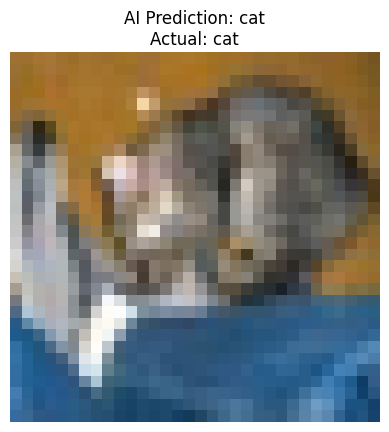

In [10]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

index = 0

prediction = model.predict(x_test[index:index+1], verbose=0)
predicted_class = np.argmax(prediction)

plt.imshow(x_test[index])
plt.axis("off")
plt.title(
    f"AI Prediction: {class_names[predicted_class]}\n"
    f"Actual: {class_names[int(y_test[index][0])]}"
)
plt.show()

Saving IMG_0485.jpeg to IMG_0485.jpeg


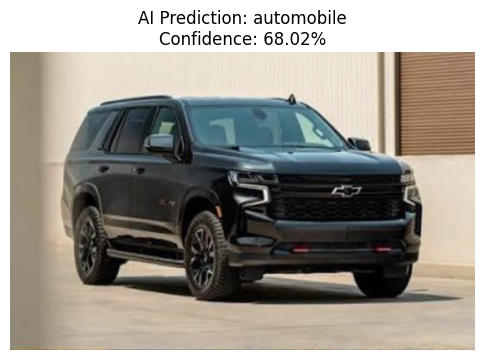

In [12]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload an image
uploaded = files.upload()

# Get the uploaded image
filename = list(uploaded.keys())[0]
image = Image.open(filename).convert("RGB")

# Prepare the image for the model
image_resized = image.resize((32, 32))
image_array = np.array(image_resized).astype("float32") / 255.0
image_array = np.expand_dims(image_array, axis=0)

# Make prediction
prediction = model.predict(image_array, verbose=0)
predicted_class = np.argmax(prediction)
confidence = np.max(prediction) * 100

# Display the image and result
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"AI Prediction: {class_names[predicted_class]}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

In [13]:
!pip -q install gradio

In [15]:
import gradio as gr
import numpy as np
from PIL import Image

def classify_image(image):
    if image is None:
        return {}

    image = image.convert("RGB")
    image_resized = image.resize((32, 32))

    image_array = np.array(image_resized).astype("float32") / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array, verbose=0)[0]

    # Get the top 3 predictions
    top_3 = np.argsort(prediction)[-3:][::-1]

    results = {
        class_names[i]: float(prediction[i])
        for i in top_3
    }

    return results


demo = gr.Interface(
    fn=classify_image,
    inputs=gr.Image(
        type="pil",
        label="📷 Upload an Image"
    ),
    outputs=gr.Label(
        num_top_classes=3,
        label="🤖 AI Predictions"
    ),
    title="🧠 AI Image Classifier",
    description=(
        "Upload an image and let the AI classify it. "
        "The model recognizes 10 categories."
    ),
    examples=None
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://76f5bb6c386c86edea.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
